### 1. Initial preparation, importing libraries and dataset

In [50]:
#data handling base
import pandas as pd
import numpy as np

#visualization
import seaborn as sns
import matplotlib.pyplot as plt

In [51]:
#import dataset from csv file
df = pd.read_csv('twcs.csv')

In [52]:
#column info
print(df.isna().sum())
print('*'*40)
print(df.info())

tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64
****************************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2811774 entries, 0 to 2811773
Data columns (total 7 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   tweet_id                 int64  
 1   author_id                object 
 2   inbound                  bool   
 3   created_at               object 
 4   text                     object 
 5   response_tweet_id        object 
 6   in_response_to_tweet_id  float64
dtypes: bool(1), float64(1), int64(1), object(4)
memory usage: 131.4+ MB
None


In [53]:
#thread root:
def get_thread_root(tweet_id, parent_map):
    visited = set()
    while tweet_id in parent_map and tweet_id not in visited:
        visited.add(tweet_id)
        tweet_id = parent_map[tweet_id]
    return tweet_id

### 2. Data preparation and cleaning

In [54]:
# find root tweets (inbound with no parent)
twroot = df[(df['inbound'] == True & df['in_response_to_tweet_id'].isna())]['tweet_id']

# sample N threads
sampled_roots = twroot.sample(n=10000, random_state=42)

# pull all tweets belonging to those threads
parent_map = df.dropna(subset=['in_response_to_tweet_id']).set_index('tweet_id')['in_response_to_tweet_id'].to_dict()

df['thread_root'] = df['tweet_id'].apply(lambda x: get_thread_root(x, parent_map))

df['is_root'] = df['in_response_to_tweet_id'].isna()
df['is_terminal'] = df['response_tweet_id'].isna()

df_sample = df[df['thread_root'].isin(sampled_roots)].copy()
df_sample.head(10)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_terminal
81,160,ChipotleTweets,False,Tue Oct 31 22:06:55 +0000 ...,@115737 My apologies for t...,NaN,161.0,163.0,False,True
82,161,115737,True,Tue Oct 31 21:59:25 +0000 ...,"@ChipotleTweets Tried, did...",160,162.0,163.0,False,False
83,162,ChipotleTweets,False,Tue Oct 31 19:51:00 +0000 ...,@115737 Give it a try. -Tara,161,163.0,163.0,False,False
84,163,115737,True,Tue Oct 31 19:43:47 +0000 ...,@ChipotleTweets can I dres...,162,NaN,163.0,True,False
673,1213,SouthwestAir,False,Tue Oct 31 22:25:25 +0000 ...,@115926 Happy HalloWN! Bot...,NaN,1214.0,1214.0,False,True
674,1214,115926,True,Tue Oct 31 22:20:26 +0000 ...,Celebrated Halloween on a ...,1213,NaN,1214.0,True,False
1665,2375,askpanera,False,Tue Oct 31 22:42:58 +0000 ...,@116252 We take food quali...,2376,2377.0,2377.0,False,False
1666,2376,116252,True,Tue Oct 31 22:44:23 +0000 ...,"@askpanera Yes, after i al...",NaN,2375.0,2377.0,False,True
1667,2377,116252,True,Tue Oct 31 22:17:57 +0000 ...,@116253 you guys call this...,2375,NaN,2377.0,True,False
2577,3504,BofA_Help,False,Tue Oct 31 22:49:08 +0000 ...,"@116538 Hello, we saw your...",NaN,3505.0,3505.0,False,True


In [55]:
df_sample["textlower"] = df_sample["text"].str.lower()

In [56]:
df_sample['created_at'] = pd.to_datetime(df_sample['created_at'])
df_sample = df_sample.sort_values(['thread_root', 'created_at'])
df_sample['turn_index'] = df_sample.groupby('thread_root').cumcount()
df_sample

C:\Users\Asus Tuf\AppData\Local\Temp\ipykernel_21496\2727281174.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample['created_at'] = pd.to_datetime(df_sample['created_at'])


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_terminal,textlower,turn_index
84,163,115737,True,2017-10-31 19:43:47+00:00,@ChipotleTweets can I dres...,162,NaN,163.0,True,False,@chipotletweets can i dres...,0
83,162,ChipotleTweets,False,2017-10-31 19:51:00+00:00,@115737 Give it a try. -Tara,161,163.0,163.0,False,False,@115737 give it a try. -tara,1
82,161,115737,True,2017-10-31 21:59:25+00:00,"@ChipotleTweets Tried, did...",160,162.0,163.0,False,False,"@chipotletweets tried, did...",2
81,160,ChipotleTweets,False,2017-10-31 22:06:55+00:00,@115737 My apologies for t...,NaN,161.0,163.0,False,True,@115737 my apologies for t...,3
674,1214,115926,True,2017-10-31 22:20:26+00:00,Celebrated Halloween on a ...,1213,NaN,1214.0,True,False,celebrated halloween on a ...,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2810760,2986961,JetBlue,False,2017-11-21 18:41:17+00:00,@221257 Sorry we missed yo...,NaN,2986962.0,2986963.0,False,True,@221257 sorry we missed yo...,2
2810939,2987139,548726,True,2017-11-21 20:21:07+00:00,@AppleSupport my iPhone X ...,2987138,NaN,2987139.0,True,False,@applesupport my iphone x ...,0
2810938,2987138,AppleSupport,False,2017-11-21 20:41:28+00:00,@548726 Hey there! Thank y...,NaN,2987139.0,2987139.0,False,True,@548726 hey there! thank y...,1
2811498,2987677,823784,True,2017-11-22 03:43:22+00:00,なんか急にアマゾンから注文してた品物配達完了メールき...,2987676,NaN,2987677.0,True,False,なんか急にアマゾンから注文してた品物配達完了メールき...,0


### 3. Descriptive analysis

In [ ]:
# pd.set_option('display.max_colwidth', 100)
# df_sample.style.set_properties(**{'text-align': 'left'})
# print(df_sample["text"].head(30))
# pd.set_option('display.max_colwidth', 30)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_terminal
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist you. We would need to get you into a private secure...,2,3.0,8.0,False,False
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so that we can further assist you. Just click ‘Message’...,3,5.0,8.0,False,False
5,6,sprintcare,False,Tue Oct 31 21:46:24 +0000 2017,"@115712 Can you please send us a private message, so that I can gain further details about your ...","5,7",8.0,8.0,False,False
7,11,sprintcare,False,Tue Oct 31 22:10:35 +0000 2017,"@115713 This is saddening to hear. Please shoot us a DM, so that we can look into this for you. -KC",NaN,12.0,18.0,False,True
9,15,sprintcare,False,Tue Oct 31 20:03:31 +0000 2017,"@115713 We understand your concerns and we'd like for you to please send us a Direct Message, so...",12,16.0,18.0,False,False


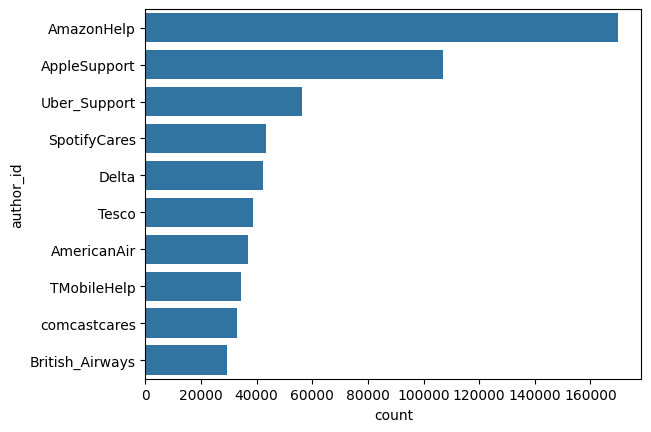

In [70]:
#filter only companies
companies = df[(df['inbound'] == False)]

#top 10 by count
order = companies['author_id'].value_counts().iloc[:10].index

#visualization
sns.countplot(companies['author_id'], order = order)

companies.head(5)

<function matplotlib.pyplot.show(close=None, block=None)>

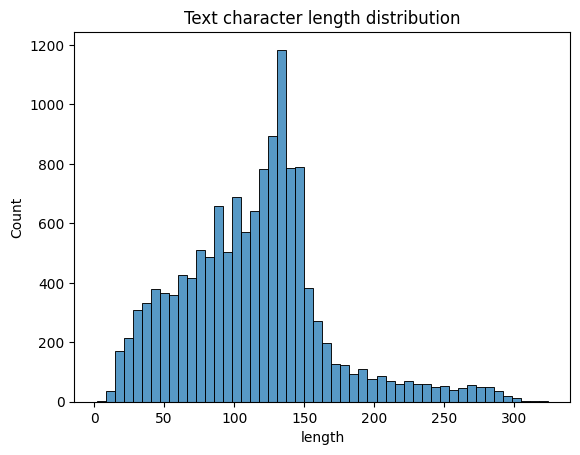

In [ ]:
df_sample['chr_length'] = df_sample['text'].str.len()
sns.histplot(df_sample['chr_length'], bins = 50)

plt.title('Text character length distribution')
plt.xlabel('length')
plt.show

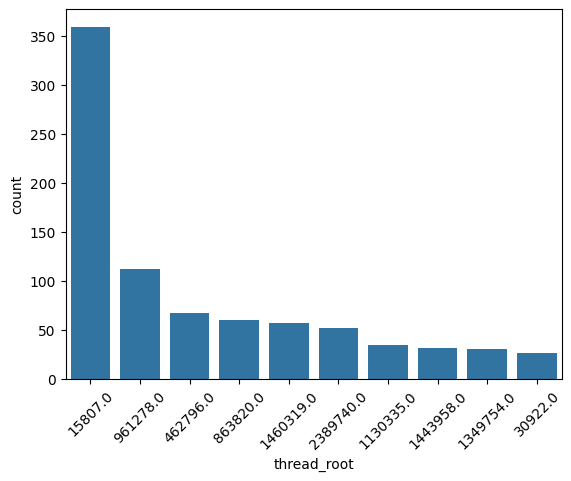

In [79]:
order1 = df_sample['thread_root'].value_counts().iloc[:10].index
sns.countplot(x = 'thread_root', data = df_sample, order = order1)
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='inbound'>

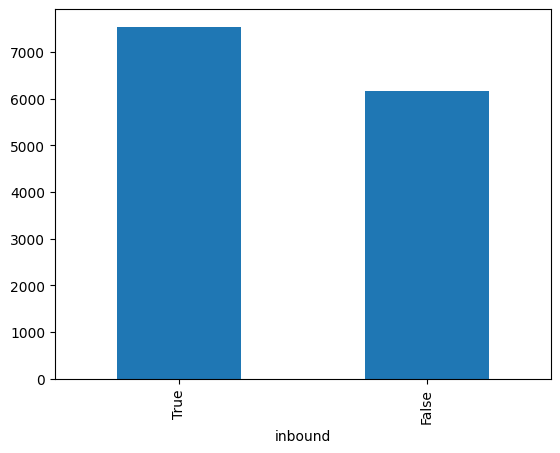

In [69]:
df_sample['inbound'].value_counts().plot(kind='bar')